[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/sklearn-unsupervised.ipynb)

# scikit-learn: Unsupervised Learning

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Prepare data correctly for k-means and PCA.</li>
<li>Choose k with several diagnostics and describe clusters in real units.</li>
<li>Test whether clusters are stable and whether they depend on preprocessing.</li>
<li>Use PCA and read variance explained and loadings.</li>
</ul>
</div>

**Prerequisites:** <a href="../sklearn-evaluation/">scikit-learn: Evaluation and Imbalanced Classes</a>. **Dataset:** Online Retail II. **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

So far every model had a **target**: default or not, price, repurchase. Unsupervised learning has none. It looks for *structure* in the inputs alone: groups of similar customers (**clustering**), or a few combined directions that capture most of the variation (**dimensionality reduction**, PCA). With no right answer to score against, evaluation is subtler, and the honest questions become: *are the groups stable, and do they depend on arbitrary choices?*

We cluster the retail customers on how recently, how often and how much they buy.

In [2]:
from mlp_data import retail, load_retail, models
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

cleaned = retail.clean_retail(load_retail())
snapshots = retail.build_splits(cleaned.sales, cleaned.returns).train
customers = snapshots[snapshots["cutoff"] == "2011-03-01"].set_index("customer_id")        # one row per active customer on 1 March 2011
features = ["recency_days", "frequency", "monetary"]
print(f"{len(customers):,} customers")
customers[features].describe().loc[["min", "50%", "max"]].round(0)

4,257 customers


,recency_days,frequency,monetary
min,0.00,1.00,2.00
50%,104.00,2.00,668.00
max,365.00,174.00,"256,119.00"


Look at the ranges: spend runs from a few pounds to over a hundred thousand, frequency from 1 to many dozens, recency from 0 to 365 days. K-means works from **distances**, so the same lesson as k-NN applies, and the heavy tail in spend and frequency needs handling first. We log-transform the skewed columns, then standardise:

In [3]:
X_raw = customers[features].to_numpy()
X_logged = np.column_stack([customers["recency_days"], np.log1p(customers["frequency"]), np.log1p(customers["monetary"])])
Z = StandardScaler().fit_transform(X_logged)
print("after log + standardise: mean", Z.mean(axis=0).round(2), "std", Z.std(axis=0).round(2))

after log + standardise: mean [-0. -0.  0.] std [1. 1. 1.]


## 1. How many clusters? Two imperfect guides

K-means needs `k` in advance. Two common diagnostics:

- **Inertia** (within-cluster sum of squares): always falls as `k` grows, so look for an "elbow" where the improvement slows.
- **Silhouette score**: for each point, how much closer it is to its own cluster than to the nearest other one (−1 to 1; higher is better separated).

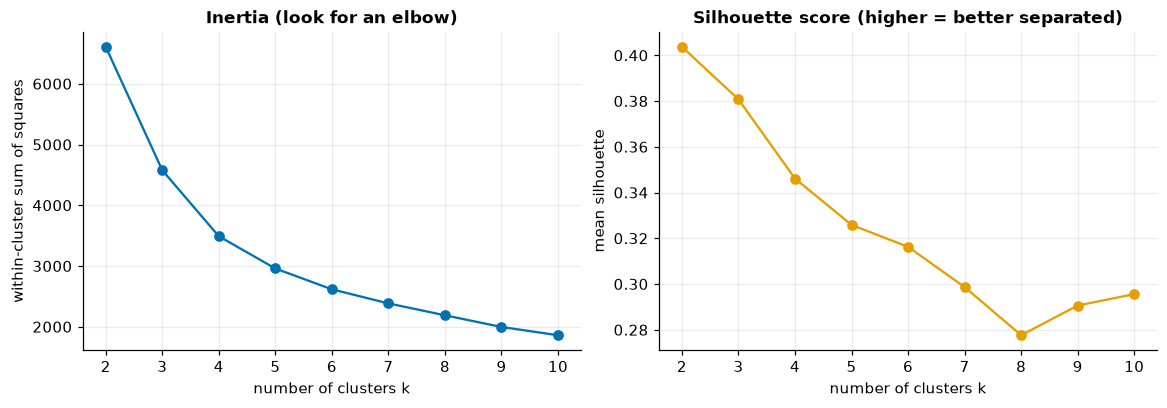

best silhouette at k = 2 (0.40)


In [4]:
ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=0))

fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.6), constrained_layout=True)
a.plot(list(ks), inertia, marker="o", color=style.BLUE); a.set(title="Inertia (look for an elbow)", xlabel="number of clusters k", ylabel="within-cluster sum of squares")
b.plot(list(ks), silhouette, marker="o", color=style.ORANGE); b.set(title="Silhouette score (higher = better separated)", xlabel="number of clusters k", ylabel="mean silhouette")
plt.show()
print("best silhouette at k =", list(ks)[int(np.argmax(silhouette))], f"({max(silhouette):.2f})")

**Reading the diagnostics.** The inertia curve bends gently around k = 3 to 4 but has no sharp elbow, and the silhouette score is **highest at k = 2** (0.40) and falls as k grows. The data has one dominant structure (active customers versus lapsed ones) and progressively weaker sub-structure. Neither diagnostic names a single winner, which is the common situation with continuous behavioural data. We choose **k = 4** because four segments are few enough to act on and different enough to matter; its silhouette (0.35) says the separation is moderate. Then we test that the choice is stable.

## 2. Fit, then *describe* the clusters

A cluster is only useful if you can say what it is. Summarise each one in the original units:

In [5]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
customers["cluster"] = km.labels_

profile = customers.groupby("cluster").agg(customers=("monetary", "size"), median_recency_days=("recency_days", "median"), median_orders=("frequency", "median"),
                                          median_spend=("monetary", "median"), total_spend=("monetary", "sum"))
profile["share of customers"] = profile["customers"] / len(customers)
profile["share of spend"] = profile["total_spend"] / profile["total_spend"].sum()
profile.drop(columns="total_spend").round(2).assign(**{"share of customers": lambda t: t["share of customers"].map("{:.0%}".format), "share of spend": lambda t: t["share of spend"].map("{:.0%}".format)})

,customers,median_recency_days,median_orders,median_spend,share of customers,share of spend
cluster,,,,,,
0,768,280.51,1.00,266.55,18%,4%
1,1453,91.34,4.00,"1,191.21",34%,26%
2,1379,111.49,1.00,316.58,32%,6%
3,657,26.67,10.00,"3,953.16",15%,64%


**Reading the profiles** (the cluster numbers 0 to 3 are arbitrary labels). Four understandable segments:

- **Cluster 3 (15% of customers):** frequent, recent, big. A median of 10 orders, 27 days since the last one, about £3,950 spent, and **64% of all spend**.
- **Cluster 1 (34%):** regulars, with a median of 4 orders, 91 days since the last, about £1,190 spent; 26% of spend.
- **Cluster 2 (32%):** one-off buyers who are not yet long gone (1 order, 111 days), about £320; only 6% of spend.
- **Cluster 0 (18%):** lapsed (1 order, 281 days since), 4% of spend.

This is the concentration we saw in the lifecycle chapter again: the smallest segment carries most of the money. A cluster is useful when it suggests an action (reward the top group, nudge the regulars, re-engage the lapsed), but remember these are *summaries of a continuum*, not natural kinds of customer.

## 3. Are the clusters real? Stability

No target, so no accuracy. But we can ask whether the answer is **reproducible**. Re-run k-means from different random starts, and on random 80% subsamples, and compare the labelings with the **adjusted Rand index** (1 = identical grouping, about 0 = unrelated):

In [6]:
rng = np.random.default_rng(0)
base = km.labels_
same_data = [adjusted_rand_score(base, KMeans(n_clusters=K, n_init=1, random_state=s).fit(Z).labels_) for s in range(1, 9)]

subsample_scores = []
for s in range(8):
    idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    sub_labels = KMeans(n_clusters=K, n_init=10, random_state=s).fit(Z[idx]).labels_
    subsample_scores.append(adjusted_rand_score(base[idx], sub_labels))

print(f"different random starts (single-init runs): ARI from {min(same_data):.2f} to {max(same_data):.2f}")
print(f"80% subsamples refitted:                    ARI from {min(subsample_scores):.2f} to {max(subsample_scores):.2f}")

different random starts (single-init runs): ARI from 0.91 to 0.98
80% subsamples refitted:                    ARI from 0.89 to 1.00


**Reading the result.** Different random starts agree with the base clustering almost perfectly (ARI 0.91 to 0.98), and refitting on random 80% subsamples agrees nearly as well (0.89 to 1.00). The four-segment grouping is **reproducible**: it is not an accident of the initialisation or of a few unusual customers. (Stable does not mean meaningful, as the next test shows.)

## 4. Does it depend on preprocessing?

Run the same algorithm on the raw, unscaled, un-logged numbers and compare with our careful version:

In [7]:
km_raw = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_raw)
raw_sizes = np.bincount(km_raw.labels_, minlength=K)
print("cluster sizes, careful version: ", sorted(np.bincount(base).tolist(), reverse=True))
print("cluster sizes, raw numbers:     ", sorted(raw_sizes.tolist(), reverse=True))
print(f"agreement between the two groupings (ARI): {adjusted_rand_score(base, km_raw.labels_):.2f}")

cluster sizes, careful version:  [1453, 1379, 768, 657]
cluster sizes, raw numbers:      [4164, 82, 9, 2]
agreement between the two groupings (ARI): 0.02


**Reading the result.** The raw-numbers version is useless: one cluster holds 4,164 of the 4,257 customers (98%) and the other three hold 82, 9 and 2. K-means spent its clusters on the handful of giant spenders because their huge values dominate every distance. Its agreement with our careful grouping is essentially zero (ARI 0.02). **The same algorithm on differently prepared data gives a completely different answer.** Segments reflect the preprocessing choices as much as the customers, so report them together.

## 5. PCA: seeing many dimensions in two

**Principal component analysis** finds the directions along which the data varies most, and rotates the data onto them. Keeping the first few gives a compact summary, and the first two give a picture. Use all the numeric behaviour features (not just three), log-transformed and standardised, so there is real multi-dimensional structure to compress.

In [8]:
from sklearn.decomposition import PCA

wide = [c for c in models.HEAVY_TAILED if c in snapshots.columns]
W = snapshots[snapshots["cutoff"] == "2011-03-01"].set_index("customer_id")[wide]
W = W.fillna(W.median())
Wz = StandardScaler().fit_transform(np.log1p(W.clip(lower=0)))

pca = PCA().fit(Wz)
explained = pca.explained_variance_ratio_
cum = explained.cumsum()
print(f"{len(wide)} features. Share of variance in the first 1, 2, 3, 5 components: {', '.join(f'{cum[i - 1]:.0%}' for i in (1, 2, 3, 5))}")
print(f"components needed to keep 90% of the variance: {int(np.searchsorted(cum, 0.90) + 1)}")

14 features. Share of variance in the first 1, 2, 3, 5 components: 46%, 62%, 74%, 86%
components needed to keep 90% of the variance: 6


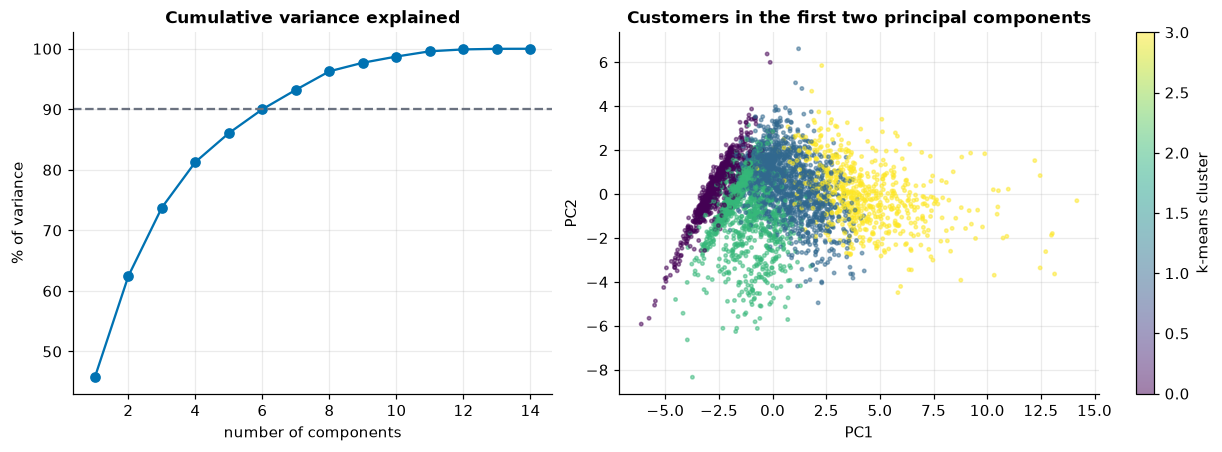

,PC1,PC2
freq_180d,0.36,-0.10
frequency,0.35,0.03
monetary,0.34,0.30
freq_90d,0.33,-0.26
monetary_90d,0.30,-0.24


In [9]:
coords = PCA(n_components=2).fit_transform(Wz)
loadings = pd.DataFrame(pca.components_[:2].T, index=wide, columns=["PC1", "PC2"])

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
a.plot(range(1, len(explained) + 1), cum * 100, marker="o", color=style.BLUE); a.axhline(90, color=style.GREY, ls="--")
a.set(title="Cumulative variance explained", xlabel="number of components", ylabel="% of variance")
scatter = b.scatter(coords[:, 0], coords[:, 1], c=customers.loc[W.index, "cluster"], cmap="viridis", s=5, alpha=0.5)
b.set(title="Customers in the first two principal components", xlabel="PC1", ylabel="PC2"); fig.colorbar(scatter, ax=b, label="k-means cluster")
plt.show()
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(5).round(2)

**Reading the output.** The first component alone captures 46% of the variance and the first three 74%; six components keep 90%. PC1's loadings are all positive and almost equal on the order-count and spend features (180-day orders, total orders, spend, 90-day orders): it is simply an **overall activity level**. PC2 contrasts spend over the whole year with *recent* (90-day) activity. In the scatter the clusters fan out along PC1 from lapsed customers on the left to heavy buyers on the right, with considerable overlap in between: a **continuum rather than separate islands**, which is exactly what the moderate silhouette suggested.

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| One giant cluster and a few tiny ones | unscaled, heavy-tailed features dominate the distance | log-transform skew, then standardise |
| The "elbow" is not visible | genuinely continuous data has no natural cluster count | use silhouette and stability; choose k for *usefulness* |
| Clusters change on every run | random initialisation; weak structure | `n_init` > 1, fix `random_state`, test stability with ARI |
| PCA dominated by one feature | unscaled features | `StandardScaler` before PCA |
| A cluster with an appealing name that means nothing | over-reading arbitrary partitions | validate against something external, or check stability |

## Check yourself

<details class="question">
<summary>1. Why must you scale before k-means or PCA, but not before a decision tree?</summary>

Both k-means and PCA are driven by distances and variances, which depend on the units: a feature measured in large numbers dominates. Trees compare each feature with a threshold, which depends only on the order of values, so units do not matter.

</details>

<details class="question">
<summary>2. The silhouette score and the inertia suggest different values of k. Which is right?</summary>

Neither is "right". They are guides, and with continuous data there is often no natural number of groups. Choose k by what is *useful* for the purpose (can you act differently for each segment?), and then check the choice is stable. Report that it is a judgement.

</details>

<details class="question">
<summary>3. What does a high adjusted Rand index between two runs tell you, and what does it not?</summary>

It tells you the grouping is **reproducible**: different starts or subsamples give nearly the same partition. It does *not* tell you the groups are meaningful or correspond to anything real; a stable partition of featureless data is still featureless. Stability is necessary, not sufficient.

</details>

## Exercises

<details class="question">
<summary>What is the silhouette score of the k=4 solution, and how does it compare with the best k you found? Does that change how much you trust the four segments?</summary>

```python
print(round(silhouette_score(Z, km.labels_, sample_size=3000, random_state=0), 3))
```

It is about 0.35, against 0.40 at k = 2 on the curve above. A modest score means the clusters overlap: customers sit on a continuum, and the segments are a convenient slicing rather than natural islands. That is fine for targeting, as long as you do not describe them as distinct "types of people".

</details>

<details class="question">
<summary>Cluster on the first three principal components of the wide feature set instead of the three RFM columns. How similar is the grouping (ARI) to the RFM one?</summary>

```python
Z_pca = PCA(n_components=3).fit_transform(Wz)
labels_pca = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(Z_pca)
print(round(adjusted_rand_score(customers.loc[W.index, "cluster"], labels_pca), 2))
```

The agreement is low (about 0.29): the segments depend substantially on which features you feed in. That is itself worth knowing before you build a strategy on them; broad ideas (active versus lapsed) survive, but the exact boundaries do not.

</details>

## Recap

- Unsupervised learning finds structure **without a target**, so you must test *stability* and *usefulness* instead of accuracy.
- Distance-based methods need **scaling**, and skewed features need a log first.
- Choose k using inertia, silhouette **and** purpose; describe each cluster in the **original units**.
- Check reproducibility with the **adjusted Rand index** across restarts and subsamples; test sensitivity to preprocessing.
- **PCA** rotates onto directions of maximum variance; check the cumulative variance explained, and standardise first.

That completes the toolkit pages. The next chapters apply these tools to time series and recommender systems.